# 05 · Explainability and deployment

Integrated Gradients token attributions for the LoRA classifier, then the ONNX / INT8 export benchmark.

In [1]:
import json, os, sys
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = os.path.abspath("..")
sys.path.insert(0, ROOT)
from src.plotting import apply_style, hbar_groups, SERIES, MUTED, TEXT_SECONDARY
from src.preprocess import TextPreprocessor

apply_style()
pd.set_option("display.precision", 3)

def metrics(name):
    with open(os.path.join(ROOT, "results", "metrics", f"{name}.json"), encoding="utf-8") as f:
        return json.load(f)

def split(task, name):
    return TextPreprocessor.load_jsonl(os.path.join(ROOT, "data", "processed", task, f"{name}.jsonl"))

In [2]:
expl = metrics("explanations")
print(f"{len(expl)} sentences explained; mean |convergence delta| {np.mean([e['convergence_delta'] for e in expl]):.3f}")
per_class = {}
for e in expl:
    for w, v in zip(e["words"], e["attributions"]):
        if w.isalpha() and len(w) > 2:
            per_class.setdefault(e["predicted"], {}).setdefault(w.lower(), []).append(v)

72 sentences explained; mean |convergence delta| 0.050


## Words that push the model towards each class

Mean attribution across all test and challenge sentences predicted as that class (words seen at least twice).

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


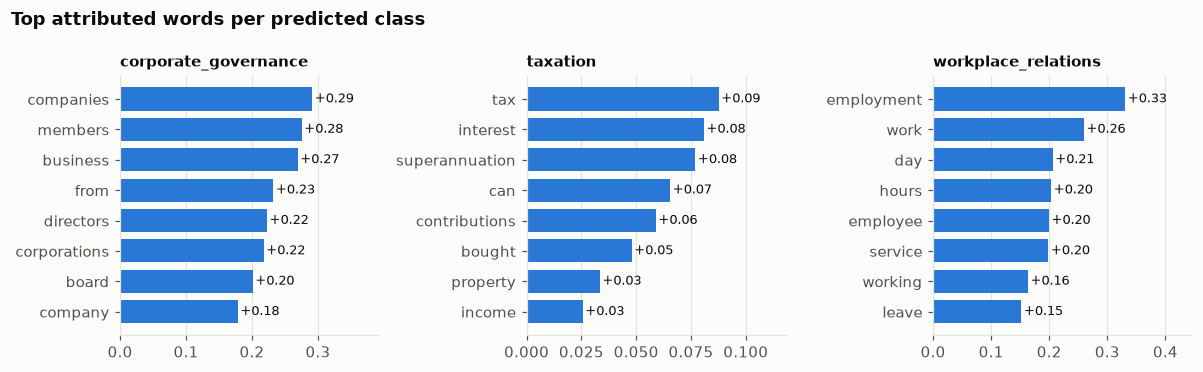

In [3]:
classes = sorted(per_class)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, cls_name in zip(axes, classes):
    top = sorted(((w, np.mean(v)) for w, v in per_class[cls_name].items() if len(v) >= 2), key=lambda x: -x[1])[:8]
    hbar_groups(ax, [w for w, _ in top], {"attribution": [s for _, s in top]}, fmt="{:+.2f}",
                xlim=(0, max(s for _, s in top) * 1.35))
    ax.set_title(cls_name, fontsize=10)
fig.suptitle("Top attributed words per predicted class", x=0.01, ha="left", fontweight="semibold")
fig.tight_layout()

## Misclassified sentences and their most influential words

In [4]:
wrong = [e for e in expl if e["gold"] != e["predicted"]]
pd.DataFrame([{"split": e["split"], "text": e["text"], "gold": e["gold"], "predicted": e["predicted"],
               "top words": ", ".join(w for w, _ in sorted(zip(e["words"], e["attributions"]), key=lambda x: -abs(x[1]))[:4])}
              for e in wrong])

,split,text,gold,predicted,top words
0,challenge,"My company car is mostly used on weekends, wil...",taxation,workplace_relations,"weekends, boss, on, extra"
1,challenge,How much do I need to earn before I have to st...,taxation,workplace_relations,"i, the, have, before"
2,challenge,Can I claim the electricity I use while workin...,taxation,workplace_relations,"kitchen, working, table, i"
3,challenge,What happens if I pay my quarterly instalment ...,taxation,workplace_relations,"late, month, instalment, if"
4,challenge,The business is running out of cash and can't ...,corporate_governance,workplace_relations,"directors, trading, ,, ?"
5,challenge,"I own six percent of a listed miner, do I have...",corporate_governance,workplace_relations,"own, miner, ,, six"
6,challenge,An employee reported fraud by the chief execut...,corporate_governance,workplace_relations,"employee, how, an, ?"
7,challenge,Shareholders voted against the pay report twic...,corporate_governance,workplace_relations,"shareholders, ,, happens, the"


## ONNX Runtime export and dynamic INT8 quantisation (CPU, batch size 1)

Size and latency use different units, so they are separate charts rather than one dual-axis plot.

,size_mb,accuracy %,agreement %,median ms
PyTorch FP32,417.7,88.889,100.000,21.42
ONNX Runtime FP32,417.9,88.889,100.000,16.83
ONNX Runtime INT8 (dynamic),105.2,91.667,94.444,7.47


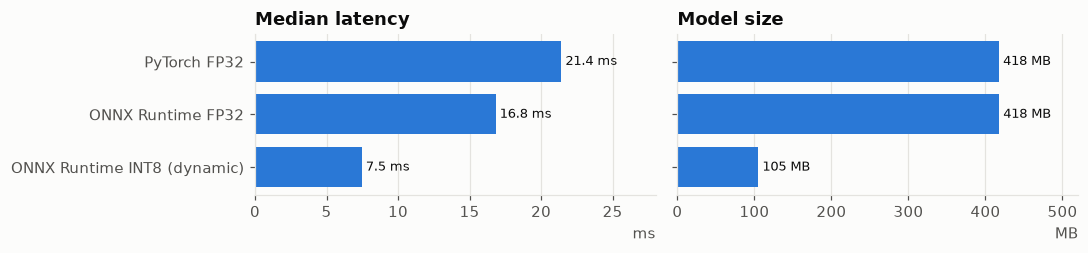

In [5]:
ex = metrics("export")
et = pd.DataFrame({k: {"size_mb": v["size_mb"], "accuracy %": 100 * v["accuracy"], "agreement %": 100 * v["agreement"],
                       "median ms": v["latency_ms_median"]} for k, v in ex.items()}).T
fig, axes = plt.subplots(1, 2, figsize=(10, 2.4))
hbar_groups(axes[0], list(et.index), {"median latency": et["median ms"].tolist()}, fmt="{:.1f} ms", xlabel="ms", xlim=(0, 28))
axes[0].set_title("Median latency")
hbar_groups(axes[1], list(et.index), {"size": et["size_mb"].tolist()}, fmt="{:.0f} MB", xlabel="MB", xlim=(0, 520))
axes[1].set_yticklabels([])
axes[1].set_title("Model size")
fig.tight_layout()
et